In [1]:
using MAT, DataFrames, Statistics, Plots, LinearAlgebra, JLD2


In [2]:
include("blp.jl")
using .blp

In [3]:

d1 = matread("../build/input/public/simulation/10markets3products.mat")
d2 = matread("../build/input/public/simulation/100markets3products.mat")
d3 = matread("../build/input/public/simulation/100markets5products.mat")
Base.active_project()

"/Users/erickom/.julia/environments/v1.12/Project.toml"

In [4]:
function process_data(d)

    J, T = size(d["P_opt"])
    p = reshape(d["P_opt"], (T*J,1));
    shares = reshape(d["shares"], (T*J,1));
    X = d["x1"]; #JTxk
    alphas = d["alphas"]; #TxR
    errors = log.(d["alphas"] .- 1);
    xi = d["xi_all"]; #JxR
    w = d["w"]; #JTx1
    Z_cost = d["Z"]; #JTx1
    omega = d["eta"]; #JTx1

    data = blp.BLPData(T, J, X, p, shares, errors)
    model = blp.BLPDemand(BLPData = data)

    model.xi_real = xi
    model.cost = gamma[1] .+ (gamma[2] * w + gamma[3] * Z_cost + omega) ;
    model.markup .= ((model.p - model.cost)./model.p ) ;
    model.profit = (model.p - model.cost) .* model.shares
    return model

end

process_data (generic function with 1 method)

In [5]:
beta = [5,1,1];
alpha_bar = -1;
gamma = [2,1,1];
sigma = 1.0;

In [6]:
model_ls = process_data(d1);
model = process_data(d2);
model_mp = process_data(d3);

In [7]:
# The errors for the model_mp model will be replaced by the errors in the original models to make a proper comparison
model_mp.errors = model.errors;

In [8]:
# Assigning the true parameters
model.beta .= vcat(beta,[alpha_bar]) ; 
model.sigma = sigma ;

model_mp.beta .= vcat(beta,[alpha_bar]) ; 
model_mp.sigma = sigma ;

In [9]:
# Computing delta
delta = model.X_all * model.beta + model.xi_real ;
delta_mp = model_mp.X_all * model_mp.beta + model_mp.xi_real ;

In [10]:
blp.simulate_BLP!(model, delta = delta, sigma = sigma, all = true);
blp.simulate_BLP!(model_mp, delta = delta_mp, sigma = sigma, all = true);

#### Question 6

In [11]:
using Plots
using LaTeXStrings
using Statistics
using ColorSchemes
using StatsPlots

##### A) Compare price, markups and profits

In the case with more products, prices go down, but interestingly markups seem to mantain and profits go up. The latter could be a consequence of lower costs rather than a market equilibrium effect.

In [12]:
describe(DataFrame(reshape(model.p, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,3.88577,1.40637,3.86152,2.85858,4.67563
2,x2,2.45794,1.07285,2.34746,1.73001,3.09984
3,x3,2.73594,1.1797,2.67599,1.83526,3.52928


In [13]:
describe(DataFrame(reshape(model_mp.p, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,1.95741,1.37218,1.86431,0.990264,2.84981
2,x2,2.17163,1.2935,2.2334,1.09456,2.95268
3,x3,1.2274,1.05437,1.10291,0.55904,2.00339
4,x4,1.14482,1.33106,0.763605,0.23765,1.9061
5,x5,2.9542,1.30592,2.96422,2.07107,3.9727


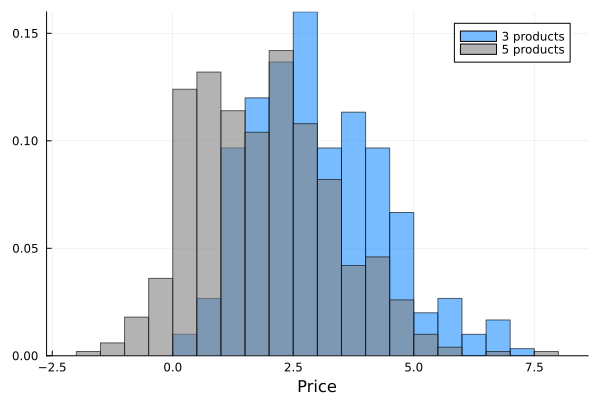

In [14]:
histogram(
    normalize = :probability,
    model.p,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    xlabel = "Price",
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.p,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :darkred,
    xlabel = "Price",
    label = "5 products"
)

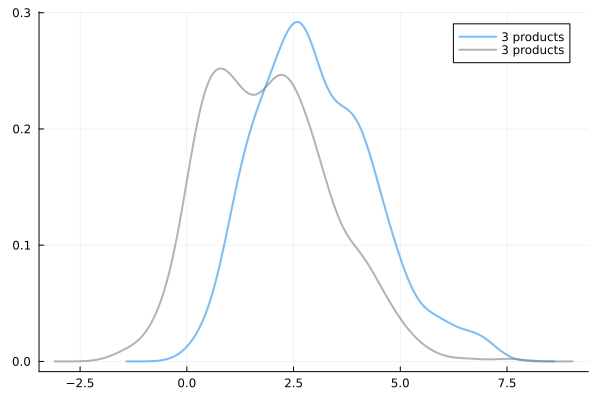

In [15]:
density(model.p, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(model_mp.p, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="3 products", 
    lw=2)

In [16]:
describe(DataFrame(reshape(model.markup, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.246187,0.165551,0.199706,0.156673,0.259881
2,x2,0.684267,0.877215,0.43892,0.270819,0.828768
3,x3,0.484761,0.56423,0.286734,0.222394,0.56477


In [17]:
describe(DataFrame(reshape(model_mp.markup, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75, :min, :max)

Row,variable,mean,std,median,q25,q75,min,max
,Symbol,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,x1,0.947322,3.61643,0.327488,0.228102,0.636039,-4.09559,34.3962
2,x2,-7.7537,84.6688,0.299379,0.223896,0.541855,-845.904,6.63568
3,x3,1.23228,7.02946,0.517821,0.295779,1.15394,-31.0054,45.1595
4,x4,0.976069,5.54463,0.579816,0.250426,1.8154,-23.7571,25.3123
5,x5,0.317444,0.572471,0.232852,0.184265,0.312278,-1.08501,5.62887


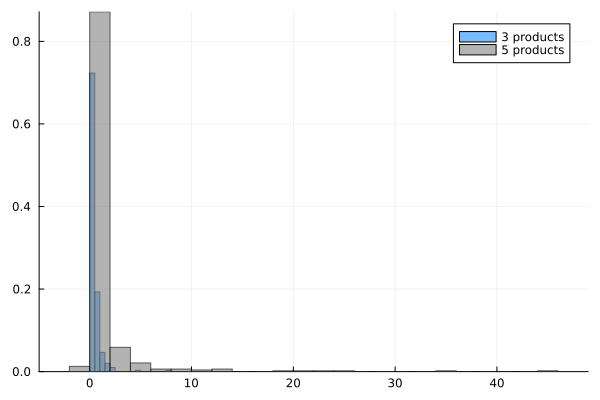

In [18]:
histogram(
    normalize = :probability,
    model.markup,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.markup[model_mp.markup .> -1, :],
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

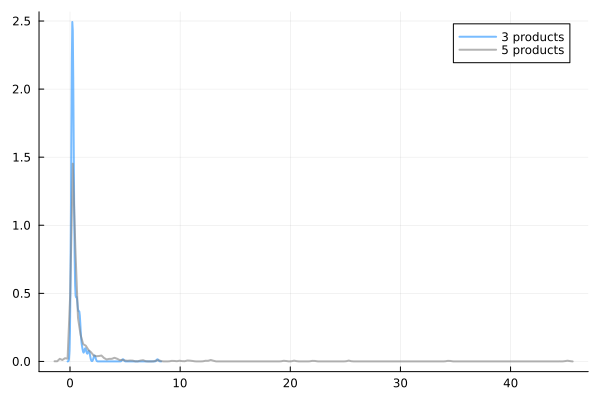

In [19]:
density(model.markup, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.markup[model_mp.markup .> -1, :], 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

In [20]:
describe(DataFrame(reshape(model.profit, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.0992899,0.177044,0.0282777,0.00691663,0.116808
2,x2,0.538401,0.603814,0.311193,0.100736,0.770478
3,x3,0.288319,0.390487,0.0999569,0.0333529,0.346653


In [21]:
describe(DataFrame(reshape(model_mp.profit, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.177263,0.408081,0.0232069,0.00458433,0.113644
2,x2,0.140031,0.27755,0.0174938,0.00205574,0.111185
3,x3,0.502255,0.75065,0.209402,0.0368337,0.536717
4,x4,0.424324,0.597818,0.177065,0.0494996,0.491452
5,x5,0.0271508,0.0691688,0.00329293,0.000564842,0.0162687


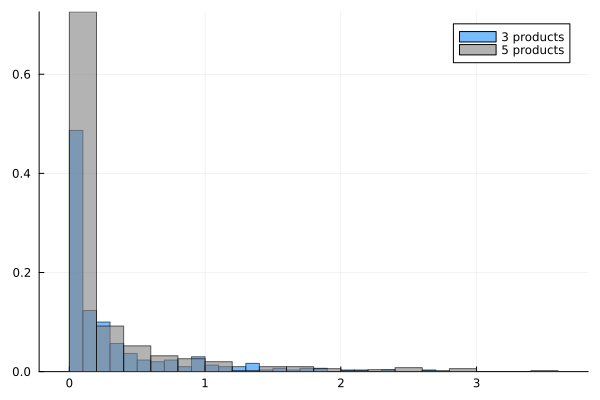

In [22]:
histogram(
    normalize = :probability,
    model.profit,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.profit,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

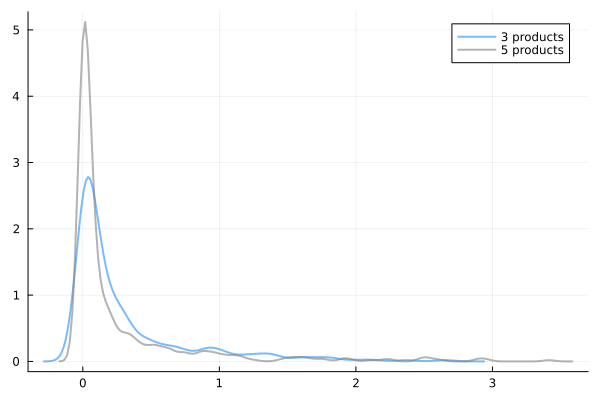

In [23]:
density(model.profit, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.profit, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

##### B) Compare Consumer Surplus

In [24]:
# Simulated are real ones with real parameters
model.cs = model.cs_sim;
model.elas = model.elas_sim;
model_mp.cs = model_mp.cs_sim;

In [25]:
describe(DataFrame(model.cs, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,1.31383,0.642036,1.25108,0.851205,1.72942


In [26]:
describe(DataFrame(model_mp.cs, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,2.76488,0.747007,2.697,2.25767,3.22767


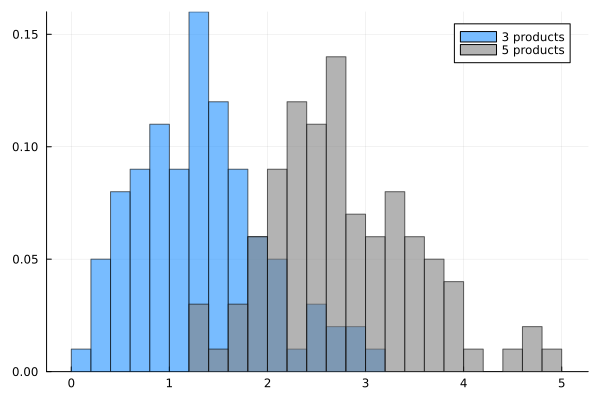

In [27]:
histogram(
    normalize = :probability,
    model.cs,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.cs,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

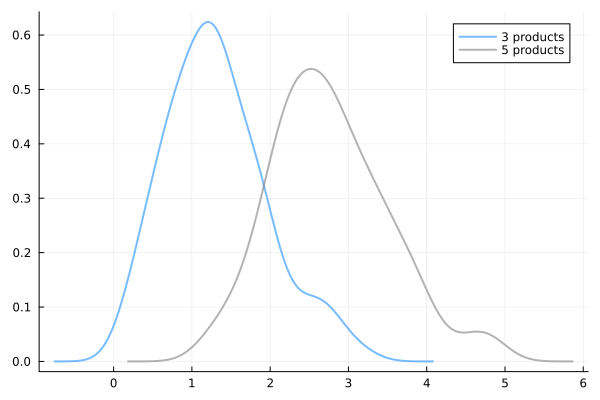

In [28]:
density(model.cs, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.cs, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

##### C) Verification of simulations

In [29]:
describe(DataFrame(model.shares - model.shares_sim, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,-3.01268e-18,7.23603e-17,0.0,-1.38778e-17,6.93889e-18


In [30]:
describe(DataFrame(model_mp.shares - model_mp.shares_sim, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,6.41694e-6,0.00481279,6.75541e-6,-0.000778736,0.000821309


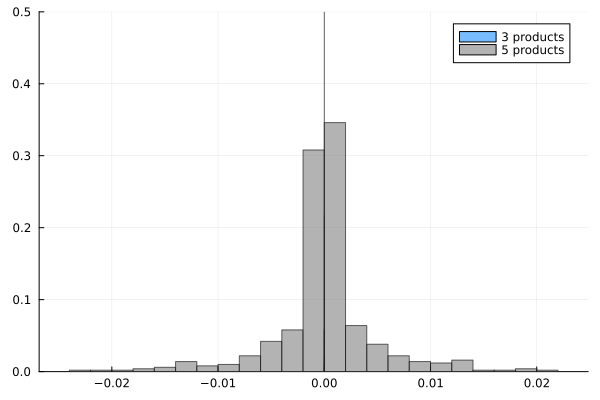

In [31]:
histogram(
    normalize = :probability,
    model.shares - model.shares_sim,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.shares - model_mp.shares_sim,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

#### Question 7

##### A)

In [32]:
# E(ξ_{jt}x_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt}x_{jt}

# Features are assumed to be exogenous
model.xi_real' * model.X / (model.T*model.J), model_mp.xi_real' * model_mp.X / (model_mp.T*model_mp.J)



([0.04346103701850776 0.020741922402260037 0.03553150322946501], [0.05319247955708747 0.004006857253279954 0.03217115395231338])

In [33]:
# E(ξ_{jt}p_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt}p_{jt}
mean(model.p .* model.xi_real), mean(model_mp.p .* model_mp.xi_real)

(0.29495813714897284, 0.1741507848822992)

In [34]:
price_bar = blp.compute_hausman(model);
price_bar_mp = blp.compute_hausman(model_mp);

In [35]:
# E(ξ_{jt}p̄_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt} p̄_{jt}
mean(price_bar .* model.xi_real), mean(price_bar_mp .* model_mp.xi_real)

(0.14367954767468016, 0.0611274048731672)

##### B)

From these moments, the only theoretical valid are the first (xi times characteristics) and the last:
- The first moment is valid under the assumption that characteristics are exogenous. However, if products have enodgenous characteristics, that respond demand to xi, the instrument wouldn't be valid.
- The second moment is invalid, the prices are endogenous. Higher xi would imply more market power, which implies a greater price charged.
- The third moment is valid under specific assumption. The logic behind the Hausman instruments is that they are shocks that most shocks shared among markets come from cost/supply side. Demand shocks are specific to each market. Under that scenario, prices from other markets are reflecting supply side condiions that can help identify the demand in each market.

##### C)

In [36]:
X_rivals = blp.compute_blp(model);
X_rivals_mp = blp.compute_blp(model_mp);

In [37]:
mean(X_rivals .* model.xi_real, dims = 1), mean(X_rivals_mp .* model_mp.xi_real, dims = 1)

([0.045690439794137144 -0.008732902789657897], [0.11649356075511394 0.1560768173100903])

#### Question 8

##### A)

In [38]:
# Total utility for each simulation
model.util




300×500 Matrix{Float64}:
  -4.36396   -32.4279     -7.61449   -21.0961    …  -22.1767     -12.8079
   4.74563    -3.79643     3.75624    -0.347277      -0.676178     2.17547
   3.17414    -7.32069     1.95857    -3.08304       -3.48713      0.0164276
   5.07565    -0.611962    2.44707     4.32876       -1.85987     -0.39756
   4.53594     1.83854     3.28932     4.18172        1.24672      1.94023
   6.13886     3.47478     4.90764     5.78902   …    2.89026      3.57521
   0.835022   -1.87062     2.09574     3.16893        0.511424    -0.747347
   0.86344    -1.47309     1.95217     2.87895        0.583988    -0.503057
   2.43859     1.86189     2.70731     2.93606        2.36962      2.10131
 -22.5974     -1.38392   -24.2382     -7.34203       -1.69848     -0.47365
  -7.16503     2.96094    -7.94821     0.116917  …    2.81079      3.39544
 -11.3252      1.46969   -12.3148     -2.12395        1.27996      2.01872
  -6.73568    -0.629301   -7.51485    -0.386803      -0.700876    -1.190

In [39]:
model.X_all * model.beta + model.xi_real

300×1 Matrix{Float64}:
 -1.4518641019760865
  5.632010385203628
  4.263150150693943
  5.480568646894691
  4.727975252367814
  6.32852668685549
  4.1095050355533855
  3.6912078300770457
  3.1365382949109684
  0.13530108590994772
  3.6861180324693716
  2.3860066886297684
  2.0023149221826024
  ⋮
  3.210600704297366
  3.4169388341460767
  1.7310751335505226
  1.3296334430348735
  3.2198178904640957
  2.6374733223690496
  0.9965828784331713
  3.0556204805842095
  2.2903017718958654
  3.0440200931364525
  4.609945586530993
  4.994262609567306

In [40]:
# Delta comming from X_all*beta (includes centered parameter of the price)
model.delta

300×1 Matrix{Float64}:
 -1.4518641019760865
  5.632010385203628
  4.263150150693943
  5.480568646894691
  4.727975252367814
  6.32852668685549
  4.1095050355533855
  3.6912078300770457
  3.1365382949109684
  0.13530108590994772
  3.6861180324693716
  2.3860066886297684
  2.0023149221826024
  ⋮
  3.210600704297366
  3.4169388341460767
  1.7310751335505226
  1.3296334430348735
  3.2198178904640957
  2.6374733223690496
  0.9965828784331713
  3.0556204805842095
  2.2903017718958654
  3.0440200931364525
  4.609945586530993
  4.994262609567306

In [41]:
# Utility from the individual part
model.util .- model.delta

300×500 Matrix{Float64}:
  -2.9121    -30.9761     -6.16263   …   -5.23416   -20.7248    -11.3561
  -0.886378   -9.42844    -1.87577       -1.59316    -6.30819    -3.45654
  -1.08901   -11.5838     -2.30458       -1.95737    -7.75028    -4.24672
  -0.404919   -6.09253    -3.03349       -3.9017     -7.34043    -5.87813
  -0.192036   -2.88943    -1.43866       -1.85041    -3.48126    -2.78775
  -0.189664   -2.85374    -1.42089   …   -1.82756    -3.43826    -2.75332
  -3.27448    -5.98013    -2.01376      -13.9902     -3.59808    -4.85685
  -2.82777    -5.1643     -1.73904      -12.0816     -3.10722    -4.19427
  -0.697948   -1.27465    -0.429229      -2.98198    -0.766922   -1.03523
 -22.7327     -1.51922   -24.3735        -2.31932    -1.83379    -0.608951
 -10.8511     -0.725179  -11.6343    …   -1.1071     -0.875332   -0.290674
 -13.7112     -0.916318  -14.7009        -1.3989     -1.10605    -0.367289
  -8.738      -2.63162    -9.51716       -0.438769   -2.70319    -3.19292
   ⋮       

##### B)

We have the moments as follow. For a set of instruments Z:
$$E(Z_{jt} \xi_{jt}) = 0$$

In this case we know that the shares of the data are a function of $\sigma$ and $\delta_{jt}$. From the nested fixed point we know that: 

$$\delta = \delta_(\sigma, s)$$

Where $s_{jt}$ are the observed shares in the markets. Since we can recover $\xi_{jt}$ directly from a the residual of the projection of $\delta$ onto the space of $X$ using $Z$ as instruments, we can recover $\xi_{jr}$ as:

$$M_X^Z = I - (X'Z(W)Z'X)^{-1} (X'Z(W)Z')$$
$$\xi = M_X^Z \delta$$

Hence the GMM can be written as:

$$\min_{\sigma} \left(Z' M_X^Z \delta(\sigma, s)\right)' W \left(Z' M_X^Z \delta(\sigma, s)\right)$$


##### C)

In [42]:
Z = hcat(model.X, price_bar, X_rivals);
W = inv(Z' * Z)

model.Z = Z
model.W = W


6×6 Matrix{Float64}:
  0.121843    -0.0160834     0.00128568   …  -0.0264045    -0.00114075
 -0.0160834    0.0420418     0.000513024      0.000969833  -8.71492e-5
  0.00128568   0.000513024   0.00371073      -8.94184e-5   -0.000139077
 -0.0272748   -0.00226656   -0.00053885       0.00114251    0.000262602
 -0.0264045    0.000969833  -8.94184e-5       0.0215093     0.00021149
 -0.00114075  -8.71492e-5   -0.000139077  …   0.00021149    0.00178522

In [43]:
function get_estimates!(model, name; toler = 1e-3, max_iter = 1000, Ns = 1)
    path =  "models/$(name).jdl2"
    if !isfile(path)
        if  typeof(model) == blp.BLPDemand
            blp.estimate_blp!(model, toler = toler, max_iter = max_iter, Ns = Ns)
        elseif typeof(model) == blp.BLP
            blp.estimate_blp_joint!(model, toler = toler, max_iter = max_iter, Ns = Ns)
        end
        jldsave(path; model = model)
        return model
    else
        model = load(path)["model"]
        return model
    end
end

get_estimates! (generic function with 1 method)

In [44]:
model = get_estimates!(model, "model");

##### D)

In [45]:
blp.simulate_BLP!(model, all = true);

In [46]:
model.markup_sim

300×1 Matrix{Float64}:
 0.12096021000597366
 1.1648202484328973
 0.26571139882677763
 0.29369903857186536
 0.4210604237351529
 1.302837222533258
 0.3187763560396104
 0.3244966999920765
 1.8155931790054238
 0.18032328425287927
 0.9177206566609759
 0.29118208938603646
 0.23483002741446685
 ⋮
 0.3664220815427271
 1.0777286107482063
 0.24968662976976233
 0.27486190330765164
 0.30252148620881286
 0.21401862904096355
 0.17509950756683723
 0.36608271462481445
 0.5710808647040478
 0.2606020104727935
 0.3136650786096136
 0.9156199035381369

In [47]:
model.markup

300×1 Matrix{Float64}:
 0.11817311394301196
 1.147561704852202
 0.261513187093628
 0.2881155781815464
 0.41668693536553975
 1.28823511828109
 0.31262484558485737
 0.3184654047658585
 1.7932532767448315
 0.17644175005552523
 0.9022908605070861
 0.2859514287156175
 0.2304505106540529
 ⋮
 0.35971258955077173
 1.0611921461357536
 0.24473535641971747
 0.2701627763444155
 0.2966204324338854
 0.2097815738538509
 0.1714095733630758
 0.3591691604884945
 0.561915913787402
 0.25620691825243774
 0.30829679069789273
 0.9028335268221344

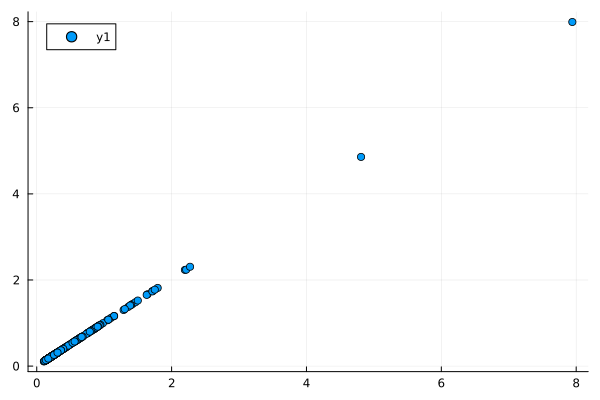

In [48]:
scatter(model.markup, model.markup_sim)

In [49]:
DataFrame(original = vec(model.markup), simulated =  vec(model.markup_sim))

Row,original,simulated
,Float64,Float64
1,0.118173,0.12096
2,1.14756,1.16482
3,0.261513,0.265711
4,0.288116,0.293699
5,0.416687,0.42106
6,1.28824,1.30284
7,0.312625,0.318776
8,0.318465,0.324497
9,1.79325,1.81559


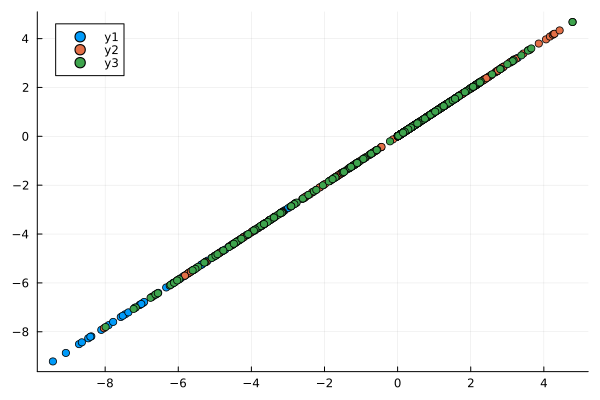

In [50]:
scatter(model.elas, model.elas_sim)

In [51]:
DataFrame(original =vec(model.elas), simulated =  vec(model.elas_sim))

Row,original,simulated
,Float64,Float64
1,-8.46216,-8.26718
2,0.000498684,0.00048724
3,0.000648924,0.000634321
4,-3.47083,-3.40485
5,0.387359,0.380096
6,0.383945,0.376727
7,-3.19872,-3.137
8,1.22111,1.19783
9,0.692608,0.679754


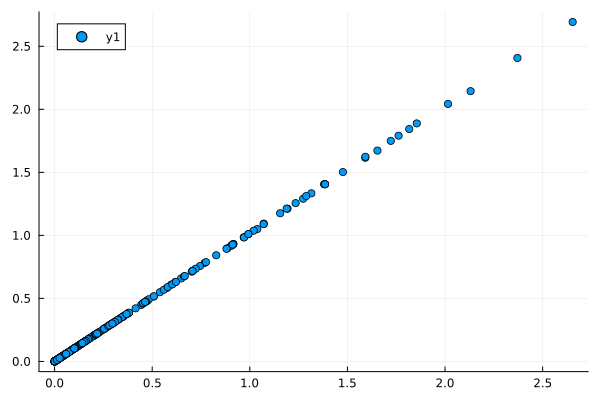

In [52]:
scatter(model.profit, model.profit_sim)

In [53]:
DataFrame(original = vec(model.profit), simulated =  vec(model.profit_sim))

Row,original,simulated
,Float64,Float64
1,3.88822e-5,3.97993e-5
2,1.59154,1.61547
3,0.0742735,0.0754659
4,0.0661418,0.0674235
5,0.0672433,0.0679491
6,1.03837,1.05014
7,0.161126,0.164296
8,0.118709,0.120957
9,0.575625,0.582796


##### E)

In [54]:
p_bar_ls = blp.compute_hausman(model_ls);
X_rivals_ls = blp.compute_blp(model_ls);

In [55]:
Z_ls = hcat(model_ls.X, p_bar_ls, X_rivals_ls);
W_ls = inv(Z_ls' * Z_ls);

In [56]:
model_ls.Z = Z_ls
model_ls.W = W_ls

6×6 Matrix{Float64}:
  4.91113    -0.419647    0.0928196  -1.62872    -0.543197    0.109699
 -0.419647    0.641522   -0.0670866  -0.0402584   0.191814   -0.0179812
  0.0928196  -0.0670866   0.045025   -0.0196178  -0.0198865   0.0141968
 -1.62872    -0.0402584  -0.0196178   0.650486    0.0090857  -0.0263591
 -0.543197    0.191814   -0.0198865   0.0090857   0.41583    -0.0443248
  0.109699   -0.0179812   0.0141968  -0.0263591  -0.0443248   0.0299857

In [57]:
model_ls = get_estimates!(model_ls, "model_ls");

In [58]:
model_ls.params

5×1 Matrix{Float64}:
  4.100611461310253
  0.49541509227319674
  1.0121580633786276
 -0.9930012190987205
  0.10000000384752493

##### F)

In [59]:
model_inc = deepcopy(model)

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

In [60]:
Z_inc = hcat(model_inc.X_all, price_bar, X_rivals);
W_inc = inv(Z_inc' * Z_inc);

model_inc.Z = Z_inc
model_inc.W = W_inc

7×7 Matrix{Float64}:
  0.12189      -0.0159803     0.00130395   …  -0.0264229    -0.00117437
 -0.0159803     0.042269      0.000553292      0.000929233  -0.000161214
  0.00130395    0.000553292   0.00371786      -9.66143e-5   -0.000152204
 -0.000323462  -0.000712616  -0.000126304      0.000127346   0.000232313
 -0.0269774    -0.00161138   -0.000422728      0.00102543    4.90154e-5
 -0.0264229     0.000929233  -9.66143e-5   …   0.0215165     0.000224725
 -0.00117437   -0.000161214  -0.000152204      0.000224725   0.00180936

In [61]:
model_inc = get_estimates!(model_inc, "model_inc");

In [62]:
model_inc.opt_res

1-element Vector{Any}:
  * Status: success

 * Candidate solution
    Final objective value:     3.832200e-01

 * Found with
    Algorithm:     Fminbox with L-BFGS

 * Convergence measures
    |x - x'|               = 5.33e-11 ≰ 0.0e+00
    |x - x'|/|x'|          = 5.26e-11 ≰ 0.0e+00
    |f(x) - f(x')|         = 1.56e-12 ≰ 0.0e+00
    |f(x) - f(x')|/|f(x')| = 4.07e-12 ≰ 0.0e+00
    |g(x)|                 = 1.55e-11 ≤ 1.0e-08

 * Work counters
    Seconds run:   21  (vs limit Inf)
    Iterations:    4
    f(x) calls:    20
    ∇f(x) calls:   20
    ∇f(x)ᵀv calls: 0


In [63]:
model_inc.sigma


1.0143175105234712

In [64]:
model_inc.beta

4×1 Matrix{Float64}:
  4.865007618232219
  0.9441366281144613
  1.0358669363511586
 -0.9242087070592976

#### Question 9

##### A)

In [65]:
model_ss = deepcopy(model)

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

In [66]:
Z_ss = hcat(model_ss.X, price_bar, X_rivals, d2["w"])
W_ss = inv(Z_ss' * Z_ss)

7×7 Matrix{Float64}:
  2.24406       0.00846886    0.00100756   …  -0.000451011   0.562425
  0.00846886    0.0423258     0.000509806     -7.91695e-5    0.00650677
  0.00100756    0.000509806   0.00371076      -0.000139167  -7.37061e-5
 -0.754328     -0.0106779    -0.00044357       2.63024e-5   -0.192682
 -0.039426      0.000819185  -8.77119e-5       0.000207258  -0.00345092
 -0.000451011  -7.91695e-5   -0.000139167  …   0.00178544    0.000182794
  0.562425      0.00650677   -7.37061e-5       0.000182794   0.149052

In [67]:
model_ss.Z = Z_ss
model_ss.W = W_ss

7×7 Matrix{Float64}:
  2.24406       0.00846886    0.00100756   …  -0.000451011   0.562425
  0.00846886    0.0423258     0.000509806     -7.91695e-5    0.00650677
  0.00100756    0.000509806   0.00371076      -0.000139167  -7.37061e-5
 -0.754328     -0.0106779    -0.00044357       2.63024e-5   -0.192682
 -0.039426      0.000819185  -8.77119e-5       0.000207258  -0.00345092
 -0.000451011  -7.91695e-5   -0.000139167  …   0.00178544    0.000182794
  0.562425      0.00650677   -7.37061e-5       0.000182794   0.149052

In [68]:
model_ss = get_estimates!(model_ss, "model_ss");

##### B)

In [69]:
model_ls_ss = deepcopy(model_ls)
Z_ls_ss = hcat(model_ls_ss.X, p_bar_ls, X_rivals_ls, d1["w"])
W_ls_ss = inv(Z_ls_ss' * Z_ls_ss)


7×7 Matrix{Float64}:
  5.4207    -0.425996     0.104826    …   0.120086    -0.411559
 -0.425996   0.641601    -0.0672362      -0.0181106    0.00512803
  0.104826  -0.0672362    0.0453079       0.0144416   -0.00969716
 -1.9235    -0.0365854   -0.0265634      -0.0323676    0.238078
 -0.535018   0.191712    -0.0196938      -0.0441581   -0.00660594
  0.120086  -0.0181106    0.0144416   …   0.0301974   -0.00838891
 -0.411559   0.00512803  -0.00969716     -0.00838891   0.332395

In [70]:
model_ls_ss.Z = Z_ls_ss
model_ls_ss.W = W_ls_ss

7×7 Matrix{Float64}:
  5.4207    -0.425996     0.104826    …   0.120086    -0.411559
 -0.425996   0.641601    -0.0672362      -0.0181106    0.00512803
  0.104826  -0.0672362    0.0453079       0.0144416   -0.00969716
 -1.9235    -0.0365854   -0.0265634      -0.0323676    0.238078
 -0.535018   0.191712    -0.0196938      -0.0441581   -0.00660594
  0.120086  -0.0181106    0.0144416   …   0.0301974   -0.00838891
 -0.411559   0.00512803  -0.00969716     -0.00838891   0.332395

In [71]:
model_ls_ss = get_estimates!(model_ls_ss, "model_ss");

##### C)

In [72]:
# In the code, now the BLP Model has an Omega argument that reflects the ownership
# Perfect competition uses the matrix of zeros, where costs are equal to prices

##### D)

We will be using the results including cost shifts instruments, for each scenario we create a new object

In [73]:
model_coll = deepcopy(model_ss);
model_coll.Omega = ones(model_coll.J, model_coll.J);
blp.simulate_BLP!(model_coll, all=true);


In [74]:
DataFrame(original = vec(model.elas), simulated =  vec(model.elas))

Row,original,simulated
,Float64,Float64
1,-8.46216,-8.46216
2,0.000498684,0.000498684
3,0.000648924,0.000648924
4,-3.47083,-3.47083
5,0.387359,0.387359
6,0.383945,0.383945
7,-3.19872,-3.19872
8,1.22111,1.22111
9,0.692608,0.692608


In [75]:
model_comp = deepcopy(model_ss);
model_comp.Omega = zeros(model_comp.J, model_comp.J);
blp.simulate_BLP!(model_comp, all=true);

model_coll = deepcopy(model_ss);
model_coll.Omega = ones(model_coll.J, model_coll.J);
blp.simulate_BLP!(model_coll, all=true);

model_bert = deepcopy(model_ss);
model_bert.Omega = I(model_bert.J)
blp.simulate_BLP!(model_bert, all=true);

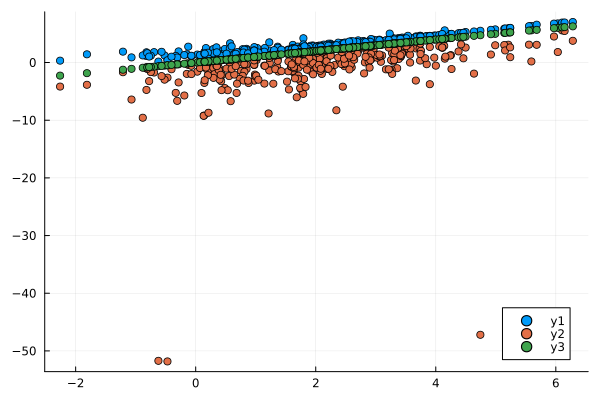

In [76]:
scatter(model.cost, model_comp.cost_sim)
scatter!(model.cost, model_coll.cost_sim)
scatter!(model.cost, model_bert.cost_sim)

##### E)

In [77]:
X_supply = hcat(ones(model.T* model.J, 1), d2["Z"], d2["w"]);
Z_supply = hcat(model.X, X_rivals, X_supply[:, 2:end]);
W_supply = inv(Z_supply' * Z_supply);

In [78]:
model_supply = blp.BLPSupply(X = X_supply, Z = Z_supply, W = W_supply);

In [79]:
model_bert_ss = deepcopy(model_ss)
model_coll_ss = deepcopy(model_ss)
model_coll_ss.Omega = ones(model_coll_ss.J, model_coll_ss.J);
model_comp_ss = deepcopy(model_ss)
model_comp_ss.Omega = zeros(model_comp_ss.J, model_comp_ss.J);

In [80]:
model_system_bert = blp.BLP(BLPDemand = model_bert_ss, BLPSupply = model_supply);
model_system_coll = blp.BLP(BLPDemand = model_coll_ss, BLPSupply = model_supply);
model_system_comp = blp.BLP(BLPDemand = model_comp_ss, BLPSupply = model_supply);

In [81]:
model_system_coll.params

0×0 Matrix{Float64}

In [82]:
model_comp_ss.Omega

3×3 Matrix{Float64}:
 0.0  0.0  0.0
 0.0  0.0  0.0
 0.0  0.0  0.0

In [83]:
model_system_bert.params

0×0 Matrix{Float64}

In [84]:
model_system_comp.opt_res

missing

In [85]:
model_system_bert = get_estimates!(model_system_bert, "model_system_bert")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [86]:
model_system_comp = get_estimates!(model_system_comp, "model_system_comp")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [87]:
model_system_coll = get_estimates!(model_system_coll, "model_system_coll")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [88]:
model_system_coll = get_estimates!(model_system_coll, "model_system_coll")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [89]:
model_system_bert.params

8×1 Matrix{Float64}:
  5.002873623314289
  0.9706362303388926
  1.0365533189855458
 -0.9798308200026781
  1.9412732539371904
  0.9169268792662337
  0.9790159293837624
  1.008754909684794

In [90]:
model_system_comp.params

8×1 Matrix{Float64}:
  5.002873623314289
  0.9706362303388926
  1.0365533189855458
 -0.9798308200026781
  2.9508737831298575
  0.7896869202700089
  0.775549040614954
  1.0042596287457943

In [91]:
model_system_coll.params

8×1 Matrix{Float64}:
  5.002873623314289
  0.9706362303388926
  1.0365533189855458
 -0.9798308200026781
 -3.127698671764429
  1.0383889546784895
  0.5458150521851588
  0.6588170170000163

#### Question 10

##### A)

I am choosing the estimates including the supply side, since they increase the precision when dealing with cost estimates.


##### B)

In [92]:
model_simul_merge = deepcopy(model_system_bert);

In [93]:
# Changing the ownership matrix and simulating
model_simul_merge.BLPDemand.Omega = [1.0 1.0 0.0;1.0 1.0 0.0;0.0 0.0 1.0];
#model_simul_merge.BLPDemand.Omega = [1.0 1.0 1.0;1.0 1.0 1.0;1.0 1.0 1.0];
blp.simulate_BLP!(model_simul_merge.BLPDemand);

In [94]:
model_simul_merge = blp.counterfactual_simulation(model_simul_merge);

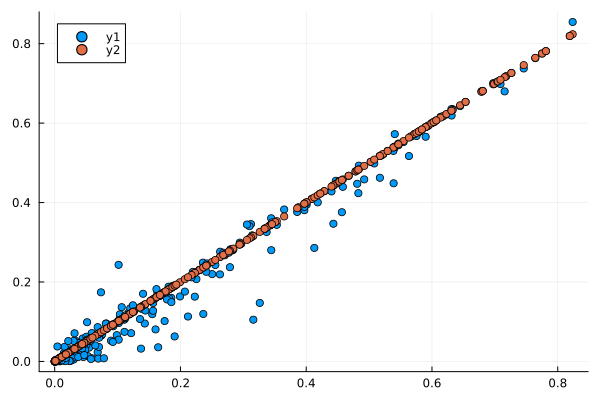

In [95]:
#Market shares for everyone
scatter(model_system_bert.BLPDemand.shares_sim, model_simul_merge.BLPDemand.shares_sim)
scatter!(model_system_bert.BLPDemand.shares_sim, model_system_bert.BLPDemand.shares_sim)

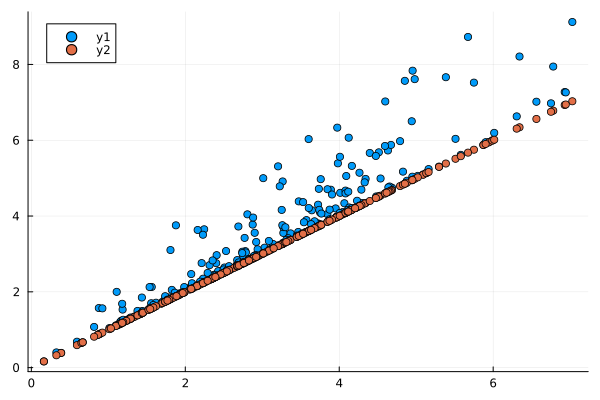

In [96]:
#Prices
scatter(model_system_bert.BLPDemand.p, model_simul_merge.BLPDemand.p)
scatter!(model_system_bert.BLPDemand.p, model_system_bert.BLPDemand.p)

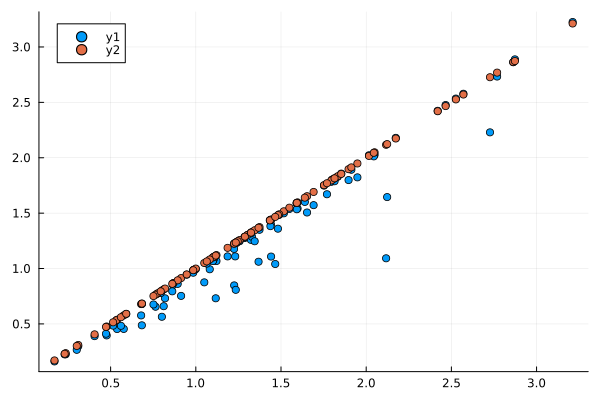

In [97]:
#Consumer surplus
scatter(model_system_bert.BLPDemand.cs_sim, model_simul_merge.BLPDemand.cs_sim)
scatter!(model_system_bert.BLPDemand.cs_sim, model_system_bert.BLPDemand.cs_sim)

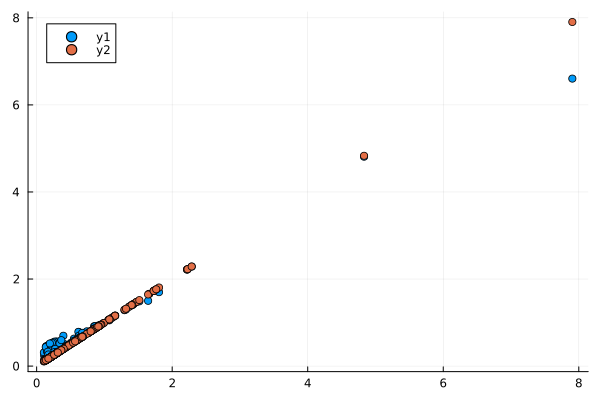

In [98]:
#Consumer surplus
scatter(model_system_bert.BLPDemand.markup_sim, model_simul_merge.BLPDemand.markup_sim)
scatter!(model_system_bert.BLPDemand.markup_sim, model_system_bert.BLPDemand.markup_sim)

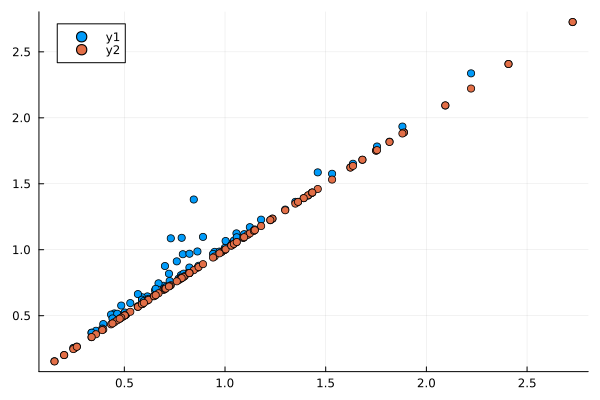

In [99]:
#Profits
scatter(model_system_bert.BLPDemand.ps_sim, model_simul_merge.BLPDemand.ps_sim)
scatter!(model_system_bert.BLPDemand.ps_sim, model_system_bert.BLPDemand.ps_sim)

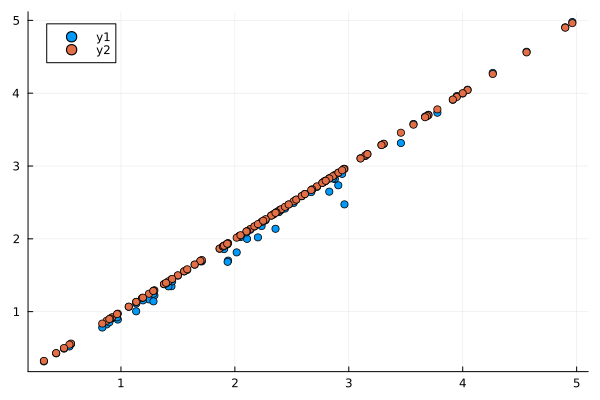

In [100]:
#Profits
scatter(model_system_bert.BLPDemand.ts_sim, model_simul_merge.BLPDemand.ts_sim)
scatter!(model_system_bert.BLPDemand.ts_sim, model_system_bert.BLPDemand.ts_sim)

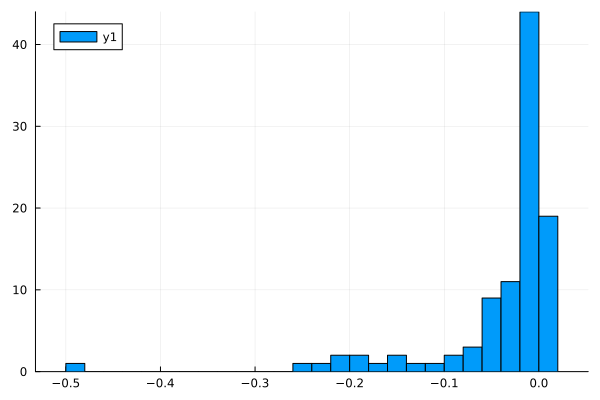

In [101]:
# Plotting the loss of surplus
histogram(model_simul_merge.BLPDemand.ts_sim - model_system_bert.BLPDemand.ts_sim)

In [102]:
# Diversion ratio is equal to

In [125]:
J = 3
T = 100

100

In [158]:
# For product one we compute the diversion ratio

idx = J * (0:T-1)

# Diversion ratio 12
D12 = model_simul_merge.BLPDemand.ds_dp[1 .+ idx, 2] ./ -model_simul_merge.BLPDemand.ds_dp[1 .+ idx, 1];
D21 = model_simul_merge.BLPDemand.ds_dp[1 .+ idx, 2] ./ -model_simul_merge.BLPDemand.ds_dp[2 .+ idx, 2];
pc1 = (model_system_bert.BLPDemand.p - model_system_bert.BLPDemand.cost_sim)[1 .+ idx]
pc2 = (model_system_bert.BLPDemand.p - model_system_bert.BLPDemand.cost_sim)[2 .+ idx]

UPP1 = D12 .* pc2;
UPP2 = D21 .* pc1;

In [ ]:
beta

In [204]:
# Comouting linear approximations of impact on profits and on consumer 

# Profits is shares time increase in price
cs_sim_linear = - (UPP1 .* model_simul_merge.BLPDemand.shares_sim[1 .+ idx] + UPP2 .* model_simul_merge.BLPDemand.shares_sim[2 .+ idx]);
ps_sim_linear = (model_simul_merge.BLPDemand.shares_sim[1 .+ idx] + model_simul_merge.BLPDemand.shares_sim[2 .+ idx]) .* UPP1 .* UPP2; 
# Impact on consumers welfare
ts_sim_linear = cs_sim_linear + ps_sim_linear;


In [205]:
Delta_cs = model_simul_merge.BLPDemand.cs_sim - model_system_bert.BLPDemand.cs_sim ;
Delta_ps = model_simul_merge.BLPDemand.ps_sim - model_system_bert.BLPDemand.ps_sim  ;
Delta_ts = model_simul_merge.BLPDemand.ts_sim - model_system_bert.BLPDemand.ts_sim ;

In [ ]:
# Price increase of product one
Delta_P1 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[1 .+ idx];
Delta_P2 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[2 .+ idx];
Delta_P3 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[3 .+ idx];

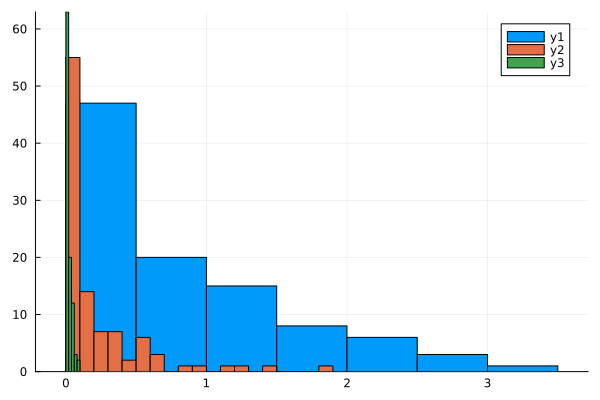

In [224]:
histogram(Delta_P1)
histogram!(Delta_P2)
histogram!(Delta_P3)

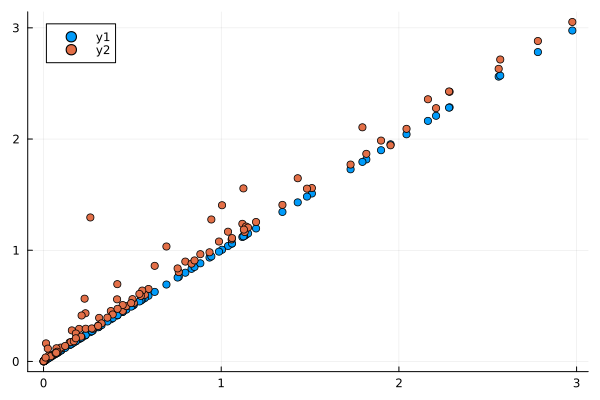

In [221]:
scatter(UPP1, UPP1)
scatter!(UPP1, Delta_P1)

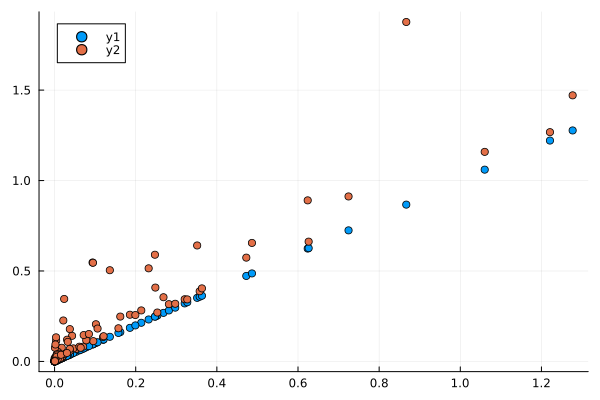

In [220]:
scatter(UPP2, UPP2)
scatter!(UPP2, Delta_P2)

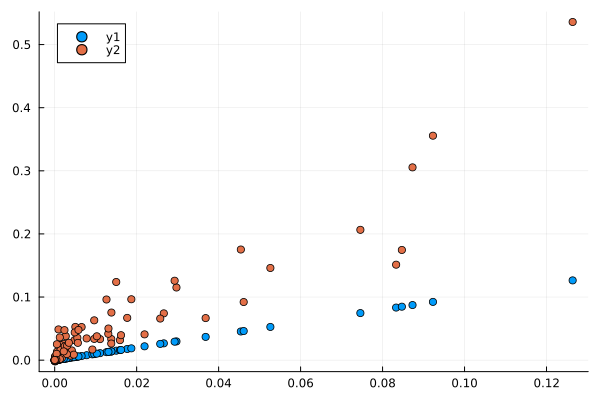

In [222]:
scatter(ps_sim_linear, ps_sim_linear)
scatter!(ps_sim_linear, Delta_ps)

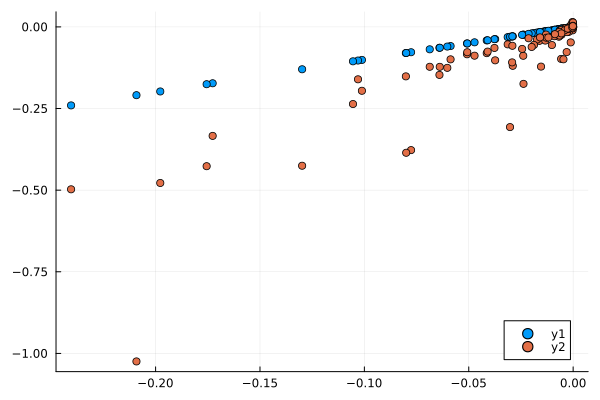

In [223]:
scatter(cs_sim_linear, cs_sim_linear)
scatter!(cs_sim_linear, Delta_cs)

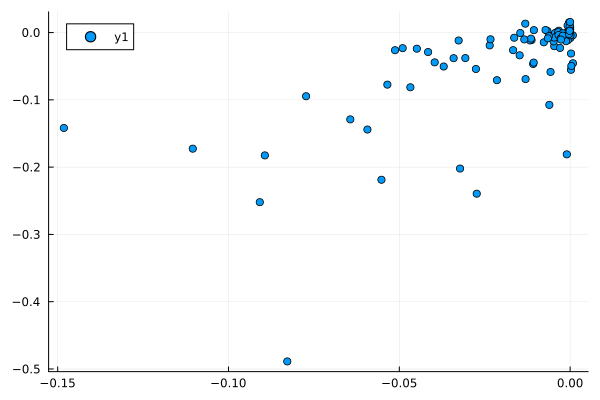

In [214]:
scatter(ts_sim_linear, Delta_ts)

##### C)

#### Question 11

##### A)

##### B)

##### C)




##### D)